# Model II
## Rozpoznawanie instrumentów za pomocą konwolucji (niezależne sieci dla każdej klasy instrumentu)

### Biblioteki

In [21]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

from model import MultiInstrumentCNN
from trening import get_device, train_model
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [33]:
epochs = 100
patience = 10
batch_size = 8
learning_rate = 0.0005

dropout2 = 0.1
dropout3 = 0.3

threshold = 0.8

In [34]:
train_dataset, val_dataset, test_dataset = create_datasets()

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

In [35]:
device = get_device()

model = MultiInstrumentCNN(num_instruments=len(INSTRUMENTS), dropout2=dropout2, dropout3=dropout3).to(device)

criterion = nn.MultiLabelSoftMarginLoss()

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [36]:
start_time = time.perf_counter()

model, history, best_epoch, best_val_loss = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=epochs,
    patience=patience,
    model_name=f"cnn2_weights_epochs_{epochs}.pth"
)

training_time = time.perf_counter() - start_time

print(f"Czas treningu: {training_time / 60:.2f} min")

Epoka 1/100 | Train loss: 0.6055 | Val loss: 0.5287
Epoka 2/100 | Train loss: 0.5178 | Val loss: 0.4812
Epoka 3/100 | Train loss: 0.4855 | Val loss: 0.4540
Epoka 4/100 | Train loss: 0.4573 | Val loss: 0.4274
Epoka 5/100 | Train loss: 0.4378 | Val loss: 0.4071
Epoka 6/100 | Train loss: 0.4191 | Val loss: 0.3957
Epoka 7/100 | Train loss: 0.4034 | Val loss: 0.3744
Epoka 8/100 | Train loss: 0.3902 | Val loss: 0.3734
Epoka 9/100 | Train loss: 0.3746 | Val loss: 0.3526
Epoka 10/100 | Train loss: 0.3618 | Val loss: 0.3304
Epoka 11/100 | Train loss: 0.3535 | Val loss: 0.3327
Epoka 12/100 | Train loss: 0.3405 | Val loss: 0.3203
Epoka 13/100 | Train loss: 0.3316 | Val loss: 0.3134
Epoka 14/100 | Train loss: 0.3230 | Val loss: 0.3112
Epoka 15/100 | Train loss: 0.3200 | Val loss: 0.2952
Epoka 16/100 | Train loss: 0.3102 | Val loss: 0.2888
Epoka 17/100 | Train loss: 0.3017 | Val loss: 0.2828
Epoka 18/100 | Train loss: 0.2951 | Val loss: 0.2854
Epoka 19/100 | Train loss: 0.2894 | Val loss: 0.2823
Ep

In [37]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        predictions = (probabilities >= threshold).astype(int)
        true_labels = y.cpu().numpy().astype(int)

        print("Prawdopodobieństwa:")
        display(pd.DataFrame(probabilities, columns=instrument_names).round(3))
        
        print("Przewidywane etykiety:")
        display(pd.DataFrame(predictions, columns=instrument_names))
        
        print("Prawdziwe etykiety:")
        display(pd.DataFrame(true_labels, columns=instrument_names))

        break

Prawdopodobieństwa:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0.933,0.397,0.884,1.0,1.000,0.697,0.987
1,0.580,0.750,1.000,1.0,0.005,0.007,0.040
2,0.000,1.000,0.000,1.0,0.005,0.823,0.005
3,0.004,0.735,0.390,1.0,0.000,0.253,0.979
4,0.999,0.185,0.977,1.0,0.946,0.852,0.024
5,1.000,0.032,0.210,0.0,0.000,0.000,1.000
6,0.007,0.048,1.000,0.0,1.000,0.104,0.175
7,0.001,0.655,0.534,1.0,0.000,0.997,0.998


Przewidywane etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,1,1,1,0,1
1,0,0,1,1,0,0,0
2,0,1,0,1,0,1,0
3,0,0,0,1,0,0,1
4,1,0,1,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,0
7,0,0,0,1,0,1,1


Prawdziwe etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,1,1,1,1,1
1,0,1,1,1,0,0,0
2,0,1,0,1,0,1,0
3,0,1,0,1,0,0,1
4,1,0,1,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,1
7,0,1,1,1,0,1,1


In [38]:
model.eval()

all_predictions = []
all_labels = []

val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        loss = criterion(logits, y)
        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_micro = f1_score(
    all_labels,
    all_predictions,
    average="micro",
    zero_division=0
)

f1_macro = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Micro-F1: {f1_micro:.4f}")
print(f"Macro-F1: {f1_macro:.4f}")

Validation loss: 0.1805
Micro-F1: 0.8970
Macro-F1: 0.8831


In [39]:
results_dir = Path("wyniki")
results_dir.mkdir(exist_ok=True)

results_file = results_dir / f"porownanie_eksperymentow_{epochs}epok.csv"

experiment = pd.DataFrame([{
    "Model": "CNN2",
    "Batch size": batch_size,
    "Learning rate": learning_rate,
    "Dropout 2": dropout2,
    "Dropout 3": dropout3,
    "Threshold": threshold,
    "Best epoch": best_epoch,
    "Best val loss": best_val_loss,
    "Micro-F1": f1_micro,
    "Macro-F1": f1_macro,
    "Training time [min]": training_time / 60
}])

if results_file.exists():
    experiment.to_csv(
        results_file,
        mode="a",
        header=False,
        index=False
    )
else:
    experiment.to_csv(results_file, index=False)

experiment

,Model,Batch size,Learning rate,Dropout 2,Dropout 3,Threshold,Best epoch,Best val loss,Micro-F1,Macro-F1,Training time [min]
0,CNN2,8,0.0005,0.1,0.3,0.8,81,0.18047,0.896996,0.883126,119.422778


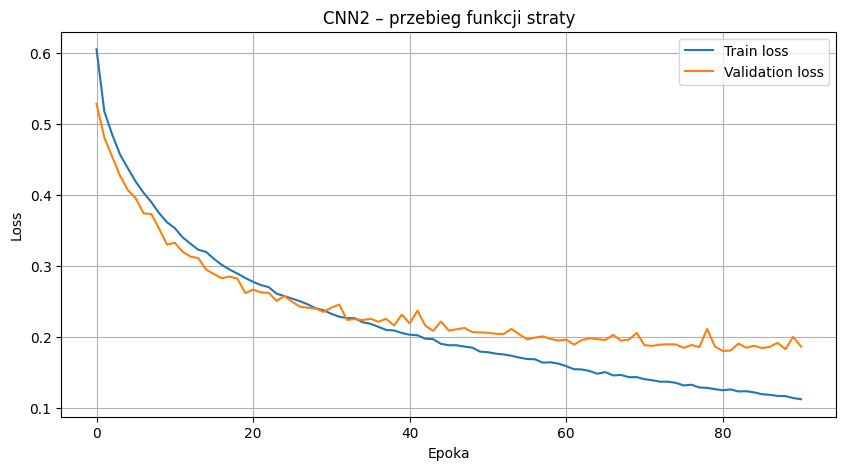

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title("CNN2 – przebieg funkcji straty")

plt.legend()
plt.grid()
plt.show()

In [41]:
f1_per_instrument = f1_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

precision_per_instrument = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall_per_instrument = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Instrument": instrument_names,
    "Precision": precision_per_instrument,
    "Recall": recall_per_instrument,
    "F1-score": f1_per_instrument
})

metrics_df

,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.984637,0.874690,0.926413
1,Saksofon altowy,0.940351,0.764622,0.843430
2,Fortepian,0.966454,0.761965,0.852113
3,Perkusja,0.998791,0.995181,0.996982
4,Gitara basowa,0.981481,0.964806,0.973072
5,Flet,0.961749,0.502140,0.659794
6,Sekcja smyczkowa,0.994358,0.873606,0.930079


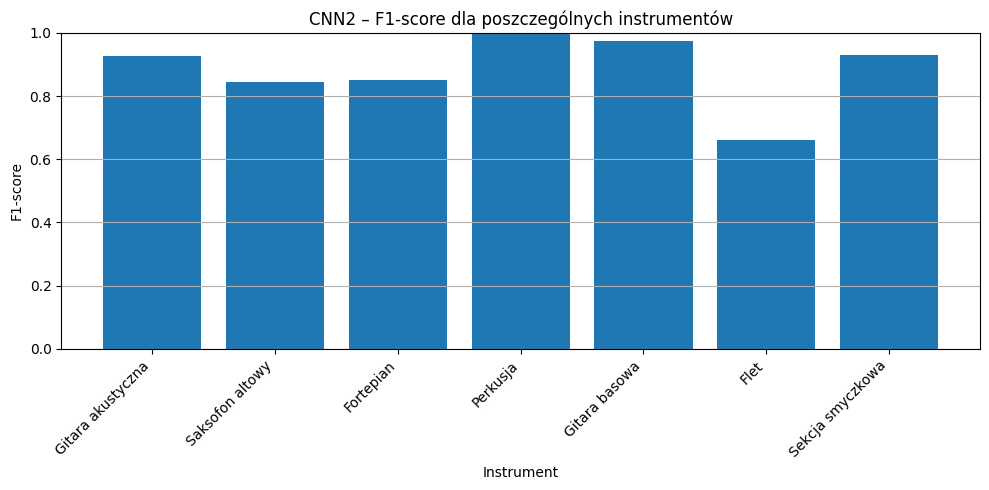

In [42]:
plt.figure(figsize=(10, 5))

plt.bar(instrument_names, f1_per_instrument)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title("CNN2 – F1-score dla poszczególnych instrumentów")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()
plt.show()